# ✈️ TravelTide – Part 3: Segments, Models & Perks

**Masterschool (MSIT) Data Analytics – Mastery Project**

Part 2 built one row per user with behavioral features. This notebook turns them into **customer segments** and matches each segment to one of Elena's five perks.

1. Rule-based segments – transparent rules in a fixed priority order, matched to perks
2. K-Means – a data-driven check: does the algorithm find the same groups without being told the rules?
3. DBSCAN and the final segment–perk table for Tableau, Streamlit and the presentation *(next step)*

## 1 – Setup & Data Loading

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
PALETTE = ["#3D90F3", "#A9CCF5", "#2E7D8C", "#1B4F8A", "#0D0F14", "#79B7F6"]
sns.set_palette(PALETTE)

# Same data folder logic as Parts 1 and 2: repo root, notebooks/ subfolder or Colab with Drive mounted
CANDIDATE_DIRS = [Path("data"), Path("../data"), Path("/content/drive/MyDrive/DS Mastery Project/data")]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.is_dir()), Path("data"))   # no folder yet → create data/ here
DATA_DIR.mkdir(exist_ok=True)
print("Data folder:", DATA_DIR.resolve())

# Google Drive backup (shared as "Anyone with the link – Viewer"), only used if a file is missing locally
DRIVE_IDS = {"users_features.csv": "1UwGBmqvTmds8_YLr4vMrrMMavQd5MkHG"}

def load_csv(name, **kwargs):   # Load a CSV file from the local data folder or Google Drive backup if missing
    if (DATA_DIR / name).exists():
        print(f"{name}: read from local folder")
        return pd.read_csv(DATA_DIR / name, **kwargs)
    if not DRIVE_IDS.get(name):
        raise FileNotFoundError(f"{name} is not in {DATA_DIR.resolve()} – run notebook 02 first (it creates this file).")
    print(f"{name}: not in the local folder → read from the Google Drive backup")
    return pd.read_csv(f"https://drive.google.com/uc?export=download&id={DRIVE_IDS[name]}", **kwargs)

users = load_csv("users_features.csv").set_index("user_id")
print(f"Users: {len(users):,} | features: {users.shape[1]}")

Data folder: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data
users_features.csv: read from local folder
Users: 5,998 | features: 35


## 2 – Rule-based segments

Each segment is defined by **one clear behavioral marker** found in Part 1. A user can match several rules (e.g. a family that also flies long-haul), so the rules are applied in a **priority order**: the first matching rule wins, and everyone who matches no rule becomes an *All-rounder*.

| # | Segment | Rule | Evidence (Part 1) |
|---|---|---|---|
| 1 | Dreamers | no valid trip | 9 % never kept a booking (5.1, 5.2.3) |
| 2 | Family Crew | has children **and** party size ≥ 1.5 | children alone ≠ family travel (5.3.1) |
| 3 | Couples & Friends | no children **and** party size ≥ 1.5 | seats ≈ rooms (5.5.4) |
| 4 | Hotel Stayers | ≥ 50 % hotel-only trips | hotel-only stays twice as long (5.4.3) |
| 5 | Weekend Escapers | ≥ 50 % Fri/Sat starts **and** ≤ 3 nights on average | no general weekend bias → user level (5.5.3) |
| 6 | Favourite-City Returners | same city at least twice | 805 repeat-city users (4.2) |
| 7 | Deal Hunters | ≥ 50 % of trips discounted **and** ≥ 2 trips | 26 % of bookings discounted (5.5.2) |
| 8 | Long-haul Packers | ≥ 1 checked bag on average **or** ≥ 3,000 km on average | long tail of long-haul flights (5.3.2) |
| – | All-rounders | everyone else | – |

**Why this order:** the most specific and least frequent markers come first, so they are not absorbed by broad rules; Long-haul Packers (the broadest rule, 2,000+ users) comes last.

**Why a 50% Threshold?**

Using 50% ("at least half of their trips") marks a clear habit rather than a one-off event, making the resulting segments intuitive to explain. 

It also fits the data (Part 2, `describe()` table in section 3):
* **Weekend & discount share:** 0.5 is exactly the 75th percentile, isolating the top quarter of bookers (30.9% and 28.4% respectively, Part 2, section 4).
* **Hotel-only share:** These trips are rarer (the 75th percentile is 0.33), so 0.5 is an even stricter threshold here, selecting 17.5% of bookers.

Ultimately, 0.5 acts as the natural dividing line between "sometimes" and "mostly."

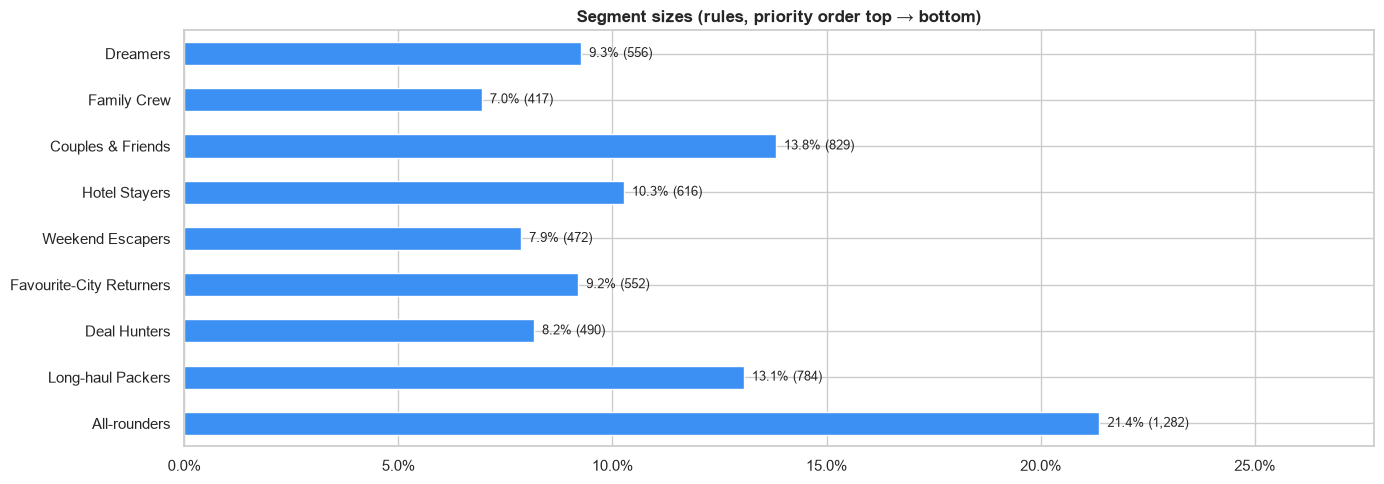

Smallest segment: 7.0 % → every segment ≥ 5 %


In [19]:
RULES = {
    "Dreamers":                 users["is_dreamer"], 
    "Family Crew":              users["has_children"] & (users["party_size"] >= 1.5), # children at home alone don't mean family travel – party size shows they travel together
    "Couples & Friends":        ~users["has_children"] & (users["party_size"] >= 1.5), # party size = larger of avg seats/rooms (r = 0.98, Part 1, 5.5.4)
    "Hotel Stayers":            users["hotel_only_share"] >= 0.5, # hotel-only bookers are a distinct segment with hotel-only stays being twice as long (Part 1, 5.4.3)
    "Weekend Escapers":         (users["weekend_start_share"] >= 0.5) & (users["avg_nights"] <= 3), # a weekend getaway is short: Fri/Sat start, back within 3 nights
    "Favourite-City Returners": users["max_visits_same_city"] >= 2, # same city (flight destination or hotel city) at least twice
    "Deal Hunters":             (users["discount_share"] >= 0.5) & (users["valid_trips"] >= 2), # users with only 1 trip are not necessarily deal hunters, even if they booked a discounted trip
    "Long-haul Packers":        (users["avg_bags"] >= 1) | (users["avg_distance_km"] >= 3000), # bags OR distance: luggage is its own behavior, not just a long-haul effect (Part 1, 5.3.4)
}
# missing values (e.g. no hotel stays → no avg_nights) count as "rule not met"
rule_flags = pd.DataFrame({name: mask.fillna(False).astype(bool) for name, mask in RULES.items()})

# first matching rule wins
users["segment"] = "All-rounders"
for name in reversed(RULES):                    # reversed: higher-priority rules overwrite lower ones
    users.loc[rule_flags[name], "segment"] = name

SEGMENT_ORDER = list(RULES) + ["All-rounders"]
sizes = users["segment"].value_counts().reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(14, 5))
shares = sizes / sizes.sum() * 100
shares.plot(kind="barh", ax=ax, color=PALETTE[0])
for i, (s, n) in enumerate(zip(shares, sizes)):
    ax.text(s, i, f"  {s:.1f}% ({n:,})", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, shares.max() * 1.3); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Segment sizes (rules, priority order top → bottom)", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Smallest segment:", f"{shares.min():.1f} %", "→ every segment ≥ 5 %" if shares.min() >= 5 else "→ below 5 %, adjust a threshold")

### 2.1 How often do the rules overlap?
The heatmap counts users who meet **two rules at once** (before the priority order). Large overlaps show where the order decides the segment – and justify putting the narrow rules first.

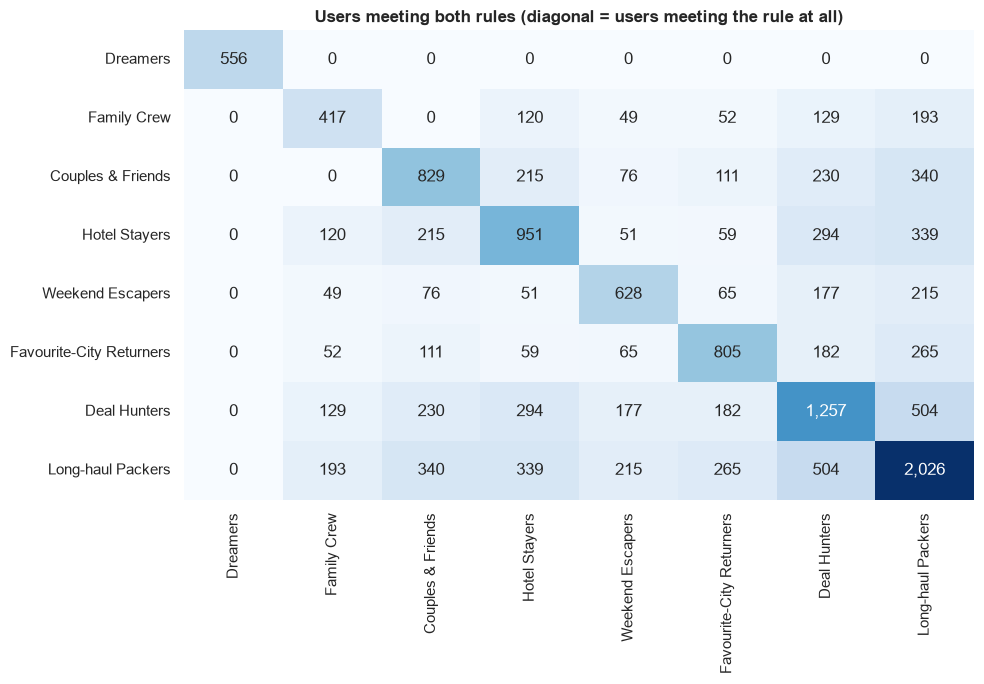

In [20]:
overlap = rule_flags.T.astype(int) @ rule_flags.astype(int)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(overlap, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax); ax.grid(False)
ax.set_title("Users meeting both rules (diagonal = users meeting the rule at all)", fontweight="bold")
plt.tight_layout(); plt.show()

### 2.2 Segment profiles
Median of the key features per segment – each segment should stand out on *its own* marker.

,users,valid_trips,party_size,avg_bags,avg_distance_km,avg_nights,hotel_only_share,weekend_start_share,discount_share,max_visits_same_city,avg_spend_per_trip_usd,age
segment,,,,,,,,,,,,
Dreamers,556,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,28.0
Family Crew,417,2.0,1.80,0.5,1957.0,4.00,0.00,0.25,0.25,1.0,1499.09,42.0
Couples & Friends,829,3.0,1.67,0.5,2032.0,4.00,0.00,0.25,0.25,1.0,1393.64,41.0
Hotel Stayers,616,2.0,1.00,0.5,2003.0,6.00,0.67,0.00,0.00,1.0,976.88,38.0
Weekend Escapers,472,2.0,1.00,0.5,2024.5,2.50,0.00,0.60,0.20,1.0,720.46,42.0
Favourite-City Returners,552,4.0,1.00,0.5,2023.5,3.80,0.00,0.25,0.25,2.0,961.49,42.0
Deal Hunters,490,3.0,1.00,0.5,2021.0,4.00,0.00,0.20,0.50,1.0,926.61,42.0
Long-haul Packers,784,2.0,1.00,1.0,2460.0,4.00,0.00,0.00,0.00,1.0,1014.38,42.0
All-rounders,1282,3.0,1.00,0.4,1857.0,3.67,0.00,0.25,0.00,1.0,873.95,42.0


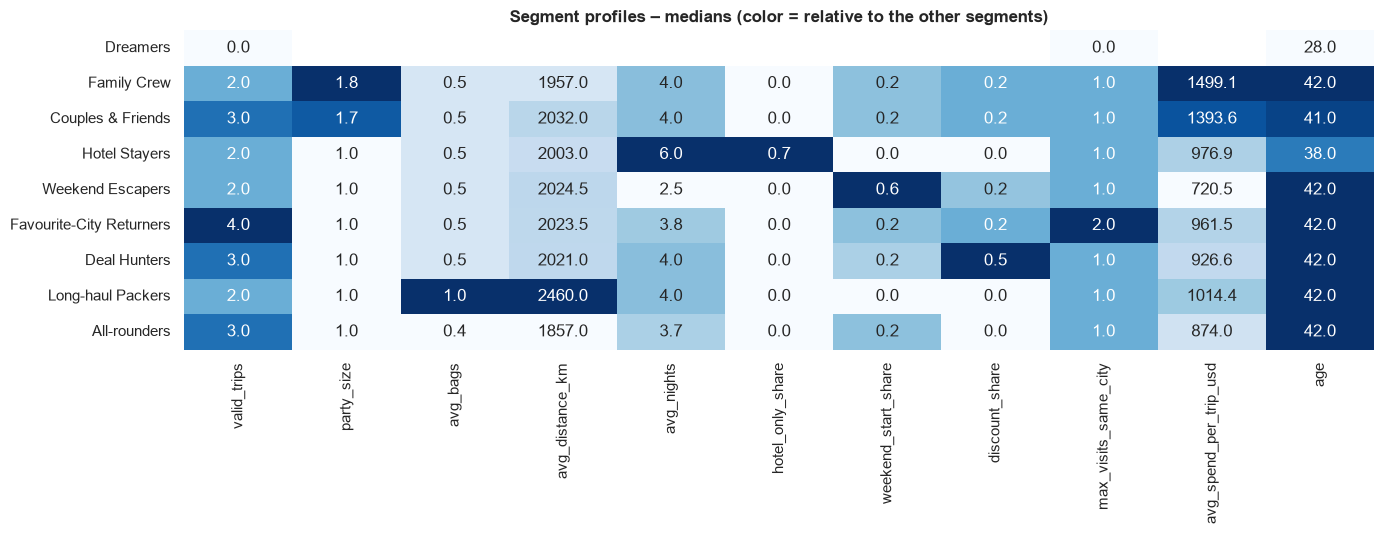

In [21]:
profile_cols = ["valid_trips", "party_size", "avg_bags", "avg_distance_km", "avg_nights", "hotel_only_share",
                "weekend_start_share", "discount_share", "max_visits_same_city", "avg_spend_per_trip_usd", "age"]
profile = users.groupby("segment")[profile_cols].median().reindex(SEGMENT_ORDER)
profile.insert(0, "users", sizes)
display(profile.round(2))

# Same profile as a heatmap: each column scaled 0–1, so the defining marker of every segment lights up
scaled = (profile[profile_cols] - profile[profile_cols].min()) / (profile[profile_cols].max() - profile[profile_cols].min())
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(scaled, annot=profile[profile_cols].round(1), fmt="", cmap="Blues", cbar=False, ax=ax); ax.grid(False)
ax.set_title("Segment profiles – medians (color = relative to the other segments)", fontweight="bold"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 3 – Perk mapping (core perks from Elena's list)
| Segment | Core perk | Pilot perk (A/B test) |
|---|---|---|
| Dreamers | No cancellation fees | 48-h Fare Lock |
| Family Crew | Free hotel meal | Family fare |
| Couples & Friends | No cancellation fees | Bring-a-friend |
| Hotel Stayers | Free hotel meal | Welcome dinner on night 1 |
| Weekend Escapers | 1 night free hotel with flight | Late Sunday check-out |
| Favourite-City Returners | 1 night free hotel with flight | City stamp card |
| Deal Hunters | Exclusive discounts | Price-drop guarantee |
| Long-haul Packers | Free checked bag | Extra-legroom seat |
| All-rounders | best-fitting perk (affinity score – next step) | – |

In [22]:
CORE_PERK = {"Dreamers": "No cancellation fees", "Family Crew": "Free hotel meal",
             "Couples & Friends": "No cancellation fees", "Hotel Stayers": "Free hotel meal",
             "Weekend Escapers": "1 night free hotel with flight", "Favourite-City Returners": "1 night free hotel with flight",
             "Deal Hunters": "Exclusive discounts", "Long-haul Packers": "Free checked bag", "All-rounders": "to be assigned"}
users["core_perk"] = users["segment"].map(CORE_PERK)
display(users["core_perk"].value_counts().to_frame("users"))

,users
core_perk,
No cancellation fees,1385
to be assigned,1282
Free hotel meal,1033
1 night free hotel with flight,1024
Free checked bag,784
Exclusive discounts,490


## 4 – K-Means: does the data find the same groups?

The rules above are my hypotheses. K-Means groups users **only by similarity of their features**, without knowing the rules. If its clusters line up with the rule segments, the segments reflect real behavior and are not just my thresholds.

**Setup decisions**
- **Bookers only (5,442 users):** Dreamers have no trip data – they are a segment by definition.
- **10 behavioral features, one per signal** (based on the correlation check in Part 2, section 5):
  - kept `avg_distance_km`, left out `long_haul_share` (r = 0.7, same signal)
  - left out `avg_session_min` and `avg_page_clicks` – engagement mainly shows *whether* someone books (Part 1, 5.1.3), and both are driven by cancellation sessions
  - left out spend – it is a result of party size and nights, not a behavior of its own
  - left out demographics (age, family status) – they describe the segments afterwards
- **Missing values → median, for K-Means only:** K-Means cannot handle empty cells. Hotel-only users have no bags or distance; the median gives them a *neutral* value, so the missing flight does not drive their cluster – `hotel_only_share` already captures that they don't fly. The saved table keeps the real empty values.
- **Standard scaling features** (mean 0, std 1): otherwise distance (thousands of km) would outweigh shares between 0 and 1.

In [23]:
KM_FEATURES = ["party_size", "avg_bags", "avg_distance_km", "avg_nights", "hotel_only_share",
               "weekend_start_share", "discount_share", "max_visits_same_city", "valid_trips", "cancel_rate"]
bookers = users[~users["is_dreamer"]].copy()
X = bookers[KM_FEATURES].fillna(bookers[KM_FEATURES].median())   # median only for the model, see above
X_scaled = StandardScaler().fit_transform(X)
print(f"K-Means input: {X_scaled.shape[0]:,} bookers × {X_scaled.shape[1]} features | "
      f"cells filled with the median: {bookers[KM_FEATURES].isna().sum().sum():,}")

K-Means input: 5,442 bookers × 10 features | cells filled with the median: 934


### 4.1 How many clusters? (k = 2 – 10)
Three checks for every k:
- **Silhouette score** (−1 to 1, higher = better): how clearly each user belongs to its own cluster rather than the next one
- **Davies-Bouldin index** (≥ 0, lower = better): how compact and well separated the clusters are
- **Inertia** (elbow): total distance of users to their cluster center – always falls with more clusters; a bend shows where extra clusters stop adding much

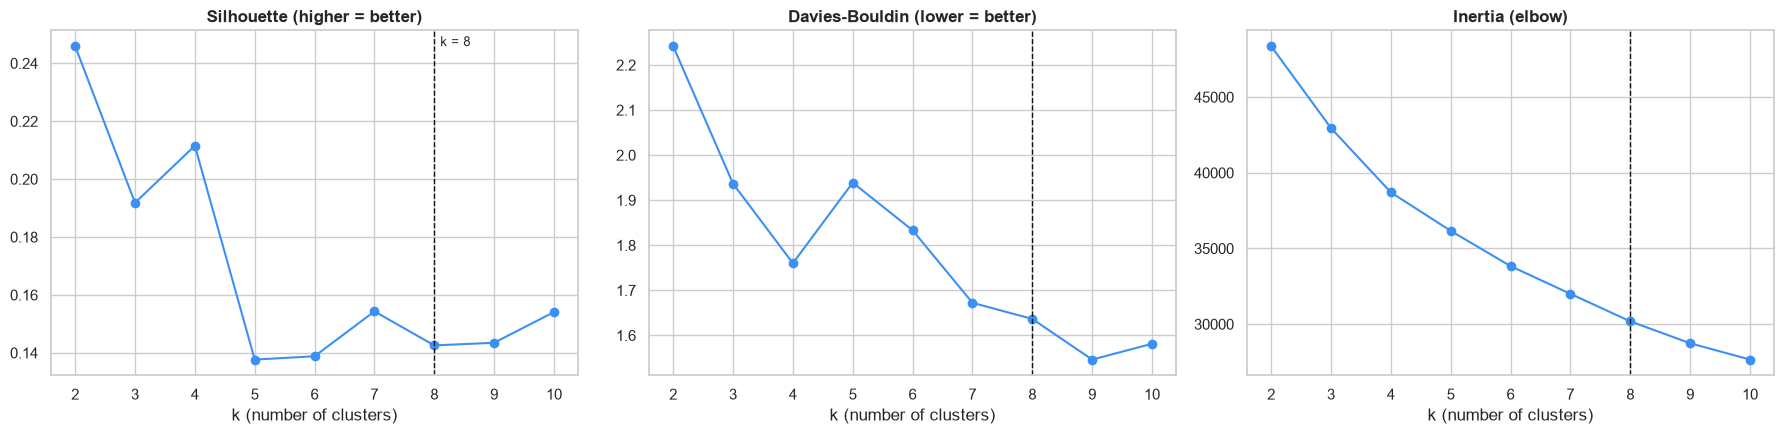

,silhouette,davies_bouldin,inertia,smallest_cluster
k,,,,
2,0.246,2.242,48366.611,997
3,0.192,1.937,42951.253,798
4,0.212,1.760,38706.567,411
5,0.138,1.939,36163.848,405
6,0.139,1.833,33834.415,400
7,0.154,1.672,32002.517,83
8,0.143,1.637,30185.030,84
9,0.143,1.546,28737.164,80
10,0.154,1.581,27659.511,81


In [24]:
scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    scores.append({"k": k, "silhouette": silhouette_score(X_scaled, km.labels_),
                   "davies_bouldin": davies_bouldin_score(X_scaled, km.labels_), "inertia": km.inertia_,
                   "smallest_cluster": np.bincount(km.labels_).min()})
scores = pd.DataFrame(scores).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, title in zip(axes, ["silhouette", "davies_bouldin", "inertia"],
                          ["Silhouette (higher = better)", "Davies-Bouldin (lower = better)", "Inertia (elbow)"]):
    ax.plot(scores.index, scores[col], marker="o", color=PALETTE[0])
    ax.axvline(8, color=PALETTE[4], ls="--", lw=1)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("k (number of clusters)")
axes[0].text(8.1, scores["silhouette"].max(), "k = 8", fontsize=9)
plt.tight_layout(); plt.show()
display(scores.round(3))

**Reading the scores:**
- All silhouette scores are **low (0.14 – 0.25)**: TravelTide's customers do not fall into sharply separated groups – behavior is a *continuum*. This is common for customer data and is the reason the perks are assigned with clear **rules**, with K-Means as a check.
- The best silhouette is at **k = 2** – but two groups cannot carry five perks. k = 4 has a small local peak.
- Davies-Bouldin keeps improving up to k = 9, the elbow has no sharp bend.

**Choice: k = 8** – the same number of groups as my booker segments (7 rule segments + All-rounders), so clusters and rules can be compared one to one. Davies-Bouldin is clearly better than at k = 4 (1.64 vs 1.76), and the smallest cluster still has 84 users.

### 4.2 What does each cluster stand for?
Average of each feature per cluster, **standardized**: 0 = average booker, +1 = one standard deviation above. The darkest cell in a row is what defines the cluster; the cluster names are generated from it.

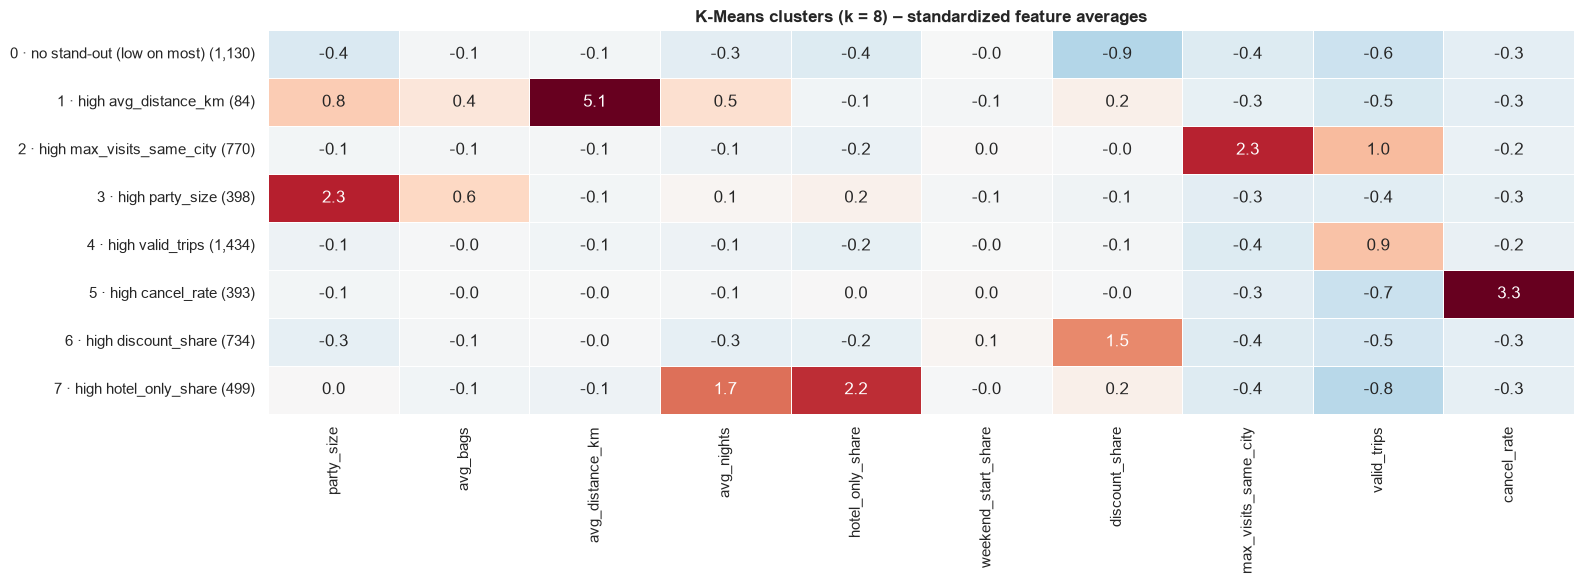

In [25]:
K = 8
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
bookers["cluster"] = kmeans.labels_

centers = pd.DataFrame(X_scaled, columns=KM_FEATURES, index=bookers.index).groupby(bookers["cluster"]).mean()
# name each cluster after its strongest feature (clusters without a value above +0.5 = "no stand-out")
top = centers.idxmax(axis=1)
names = {c: (f"high {top[c]}" if centers.loc[c, top[c]] > 0.5 else "no stand-out (low on most)") for c in centers.index}
centers.index = [f"{c} · {names[c]} ({(bookers['cluster'] == c).sum():,})" for c in centers.index]

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(centers, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-3, vmax=3, cbar=False, linewidths=0.5, ax=ax)
ax.set_title(f"K-Means clusters (k = {K}) – standardized feature averages", fontweight="bold"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 4.3 Clusters vs. rule segments
Each column is one cluster (100 %): which rule segments do its users come from? A cluster dominated by one segment means K-Means found that segment **on its own**.

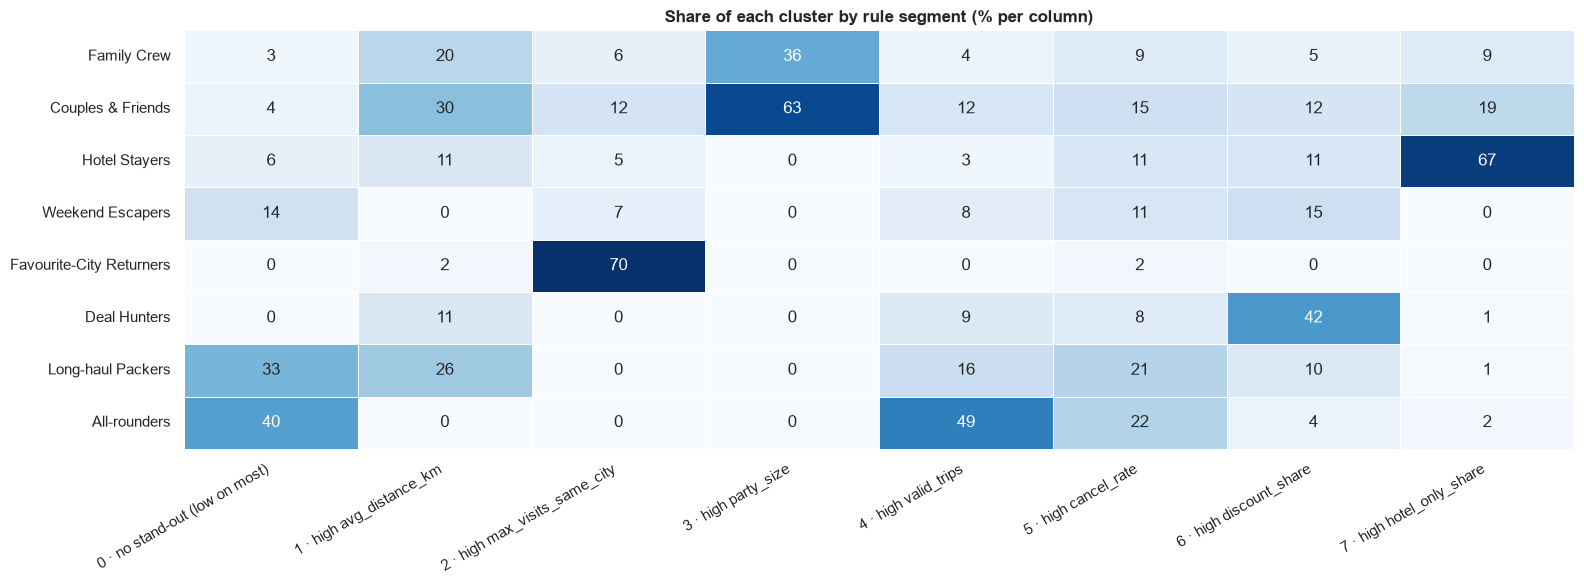

In [26]:
cross = pd.crosstab(bookers["segment"], bookers["cluster"].map(lambda c: f"{c} · {names[c]}"), normalize="columns") * 100
cross = cross.reindex([s for s in SEGMENT_ORDER if s in cross.index])

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(cross, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set_title("Share of each cluster by rule segment (% per column)", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

**What K-Means confirms – and what it doesn't** *(numbers from my run with random_state = 42)*

| Cluster defined by | Matching rule segment | Agreement |
|---|---|---|
| high `max_visits_same_city` | Favourite-City Returners | 540 of 552 returners (98 %) in one cluster |
| high `hotel_only_share` + long `avg_nights` | Hotel Stayers | two thirds of the cluster |
| high `discount_share` | Deal Hunters | the largest group in the cluster (≈ 40 %) |
| high `party_size` | Family Crew + Couples & Friends | 397 of 398 users |
| high `avg_distance_km` (≈ 8,000 km) | Long-haul Packers (extreme end) | small cluster of 84 users – only 26 % are Long-haul Packers in the rules, because half are travelling in groups and the priority order puts them in Family Crew / Couples & Friends first |
| high `cancel_rate` | – no rule segment | 393 bookers who cancel but still book → support for the **no cancellation fees** perk |
| high `valid_trips` / no stand-out | All-rounders, Long-haul Packers, Weekend Escapers | mixed |

- **5 of my 7 booker segments appear as their own cluster** – the rules describe real behavior.
- **Weekend Escapers are not found:** `weekend_start_share` is ≈ 0.3 in *every* cluster. This matches Part 1 (5.5.3): weekend starts happen at chance level, so weekend travel is a small niche, not a natural group. → candidate to merge or drop in the final segments.
- **Cancellers form a cluster without a rule** → candidate rule for the no-cancellation perk (decision for the final segments).

## 5 – Save

In [27]:
users["kmeans_cluster"] = bookers["cluster"]          # empty for Dreamers (not clustered)
users.reset_index().to_csv(DATA_DIR / "users_segments.csv", index=False)
print("Saved:", (DATA_DIR / "users_segments.csv").resolve(), "|", users.shape)

Saved: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data\users_segments.csv | (5998, 38)
